# Error analysis of Multi-MAV projection Data

This notebook analyzes projected measurements from multiple drones tracking a single target in the field. For this data from the Airship-MPC simulation from project WildCap is used. The goal is to understand the magnitudes and origins of the error and uncertainties.

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime

# third-party imports
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display
import tqdm

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils
import multi_target_tracking as mtt

# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])
importlib.reload(sys.modules['multi_target_tracking'])

# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu
import utils.visualization_utils as vu
import multi_target_tracking as mtt

Murty algorithm not available. Please install the murty package when using MHT tracking.


In [2]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

## Configuration

In [3]:
## CONFIGURATION
BAG_PATH = os.path.join(project_root, 'data/1_zebra_3_drones_with_gps_drift.bag')  # Path to the multi-drone tracking bag file
script_name = "01_error_analysis"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)
# Log to file and console
logger.info("Notebook started - Error analysis of Multi-MAV projection Data")

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
rbu.display_rosbag_info(bag_reader)

INFO: Notebook started - Error analysis of Multi-MAV projection Data


#################### Topics and message counts: ####################
Topic: /gazebo/model_states
    Message type: TopicInfo(msgtype='gazebo_msgs/msg/ModelStates', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data='# broadcast all model states in world frame\nstring[] name                 # model names\ngeometry_msgs/Pose[] pose     # desired pose in world frame\ngeometry_msgs/Twist[] twist   # desired twist in world frame\n\n================================================================================\nMSG: geometry_msgs/Pose\n# A representation of pose in free space, composed of position and orientation. \nPoint position\nQuaternion orientation\n\n================================================================================\nMSG: geometry_msgs/Point\n# This contains the position of a point in free space\nfloat64 x\nfloat64 y\nfloat64 z\n\n================================================================================\nMSG: geometry_msgs/Quaternion\n# This 

## Data Extraction and Processing

Extract data from multiple drones and ground truth for multiple targets.

In [4]:
# Define topics to analyze
topics = [
    "/machine_1/pose",
    "/machine_2/pose",
    "/machine_3/pose",
    "/machine_1/target_tracker/MTT/GT/target0",
    "/machine_1/object_detections/projected_to_world",
    "/machine_2/object_detections/projected_to_world",
    "/machine_3/object_detections/projected_to_world",
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data

INFO: Processing topic: '/machine_1/pose' with message type: 'uav_msgs/msg/uav_pose'
INFO: Processing topic: '/machine_2/pose' with message type: 'uav_msgs/msg/uav_pose'
INFO: Processing topic: '/machine_3/pose' with message type: 'uav_msgs/msg/uav_pose'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_2/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_3/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


In [5]:
# convert projected detections to measurements
t1, proj_1 = dfu.dataframe_to_measurements(topic_data["/machine_1/object_detections/projected_to_world"])
t2, proj_2 = dfu.dataframe_to_measurements(topic_data["/machine_2/object_detections/projected_to_world"])
t3, proj_3 = dfu.dataframe_to_measurements(topic_data["/machine_3/object_detections/projected_to_world"])

# get and print number of detections
num_detections_1 = len(topic_data["/machine_1/object_detections/projected_to_world"])
num_detections_2 = len(topic_data["/machine_2/object_detections/projected_to_world"])
num_detections_3 = len(topic_data["/machine_3/object_detections/projected_to_world"])
logger.info(f"Number of detections for drone 1: {num_detections_1}")
logger.info(f"Number of detections for drone 2: {num_detections_2}")
logger.info(f"Number of detections for drone 3: {num_detections_3}")

# Combine measurements for both targets
proj = proj_1.tolist() + proj_2.tolist() + proj_3.tolist()
time = t1.tolist() + t2.tolist() + t3.tolist()

# sorted by timestamp
proj = sorted(zip(time, proj), key=lambda x: x[0])

# calulate the error of the projection for each drone
err_1 = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_1/object_detections/projected_to_world"])
err_2 = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_2/object_detections/projected_to_world"])
err_3 = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_3/object_detections/projected_to_world"])

# calculate error stats for each drone
err_1_stats = dfu.calculate_position_error_statistics(err_1)
err_2_stats = dfu.calculate_position_error_statistics(err_2)
err_3_stats = dfu.calculate_position_error_statistics(err_3)
# log the error stats
logger.info(f"Error stats for drone 1: \n{err_1_stats}\n")
logger.info(f"Error stats for drone 2: \n{err_2_stats}\n")
logger.info(f"Error stats for drone 3: \n{err_3_stats}\n")

# calculate absolute of the projection for each drone
err_1_abs = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_1/object_detections/projected_to_world"], abs=True)
err_2_abs = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_2/object_detections/projected_to_world"], abs=True)
err_3_abs = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_3/object_detections/projected_to_world"], abs=True)

# clean duplicate measurements from GT
gt_zebra = dfu.clean_duplicate_timestamps(topic_data["/machine_1/target_tracker/MTT/GT/target0"])
drone1 = dfu.clean_duplicate_timestamps(topic_data["/machine_1/pose"])
drone2 = dfu.clean_duplicate_timestamps(topic_data["/machine_2/pose"])
drone3 = dfu.clean_duplicate_timestamps(topic_data["/machine_3/pose"])

INFO: Number of detections for drone 1: 546
INFO: Number of detections for drone 2: 154
INFO: Number of detections for drone 3: 572
INFO: Calculating position errors...
INFO: Calculating position errors...
INFO: Calculating position errors...
INFO: Error stats for drone 1: 
                       x           y          z       total
std             3.416417    7.107393   4.301617    8.529845
std_filtered    0.979102    0.991871   0.968548    1.559439
min           -67.066704 -153.479775 -74.401072    0.345769
max            11.363065    4.202655   3.922894  183.274395
rms             3.445751    7.108895   4.354294    9.020503
mae             1.468313    1.674805   1.721830    2.957104
outlier_ratio   0.012821    0.012821   0.012821    0.012821

INFO: Error stats for drone 2: 
                        x          y          z       total
std             10.696401   2.704601   5.402215   11.097113
std_filtered     2.994379   0.495504   1.578371    3.093235
min             -4.761886 -21.38

## Test Multi-Target Tracker (MTT) with Multiple Drones

Initialize and test the MTT class with measurements from multiple drones tracking multiple targets.

In [6]:
## STT - Single Target Tracker for reference
stt_proj_results = []
# Initialize STT with default parameters
stt_proj = mtt.SingleTargetTracker()

# Process all measurements with the single target tracker
logger.info(f"Processing {len(proj)} measurements with SingleTargetTracker")
for time, measurement in tqdm.tqdm(proj, total=len(proj), desc="STT Processing"):
    stt_proj.evaluate(time, measurement)
stt_proj_results = stt_proj.tracks[0]

## MTT - Multi-Target Tracker


# convert results to dataframe
stt_proj_results_df = dfu.track_to_dataframe(stt_proj_results)

# calculate stt error
stt_proj_error = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], stt_proj_results_df)

# calculate stt error stats
stt_proj_error_stats = dfu.calculate_position_error_statistics(stt_proj_error)
# log the error stats
logger.info(f"STT projection error stats: \n{stt_proj_error_stats}")

# calculate stt absolute error
stt_proj_error_abs = dfu.calculate_position_error(topic_data["/machine_1/target_tracker/MTT/GT/target0"], stt_proj_results_df, abs=True)

INFO: Processing 1272 measurements with SingleTargetTracker
STT Processing: 100%|██████████| 1272/1272 [00:00<00:00, 3206.01it/s]
INFO: Calculating position errors...
INFO: STT projection error stats: 
                      x         y         z     total
std            1.199131  1.022611  0.855200  1.271355
std_filtered   0.793485  0.663161  0.818569  1.223379
min           -1.026397 -1.997669 -1.218630  0.222482
max            4.358314  2.893875  3.540828  4.798268
rms            1.292053  1.052217  1.364155  2.153481
mae            0.986104  0.802738  1.073187  1.738961
outlier_ratio  0.019366  0.019366  0.019366  0.019366
INFO: Calculating position errors...


## Data Visualization

create a video using the x and y components of the drones and targets position to analyze the relative position and headings

In [7]:
# uncomment to create the video
# frame_paths = vu.visualize_tracking_data(
#     gt_zebra,
#     [drone1, drone2, drone3],
#     RESULTS_DIR,
#     fps=24,
#     drone_colors=["orange", "green", "red"],
# )

plot the targets position and the MAV detections

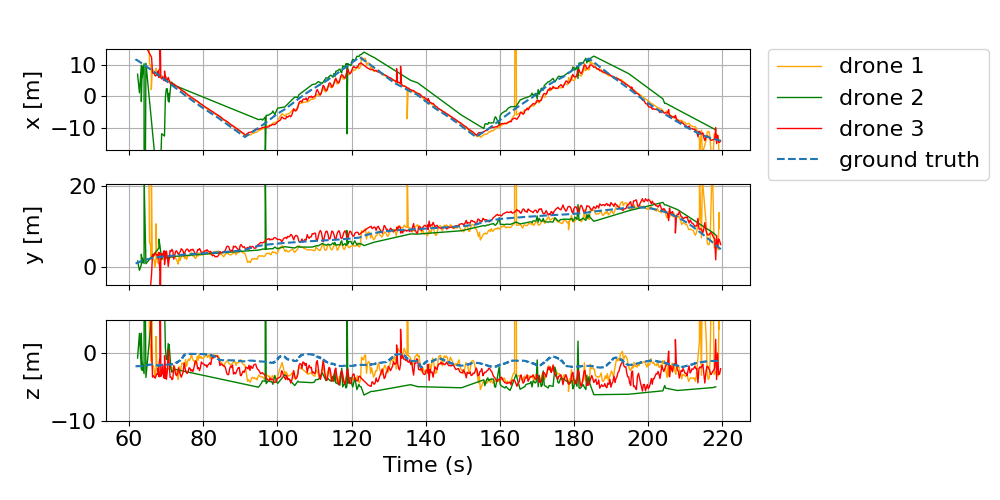

In [8]:
## plot projected detections with ground truth
fig_proj_gt = pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], label="drone 1", noisy_limits=True, show_uncertainty=False, color="orange")
pu.plot_xyz_over_time(topic_data["/machine_2/object_detections/projected_to_world"], fig=fig_proj_gt, label="drone 2", noisy_limits=True, show_uncertainty=False, color="green")
pu.plot_xyz_over_time(topic_data["/machine_3/object_detections/projected_to_world"], fig=fig_proj_gt, label="drone 3", noisy_limits=True, show_uncertainty=False, color="red")
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], fig=fig_proj_gt, label="ground truth", linestyle="--", linewidth=1.5)
# Add legend with better positioning
handles, labels = fig_proj_gt.axes[0].get_legend_handles_labels()
fig_proj_gt.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.925))
# fig_gt_drones.legend(handles, labels, loc='upper right')
# fig_gt_drones.suptitle("Ground Truth and Projected Measurements")
fig_proj_gt.set_size_inches(10, 5)
fig_proj_gt.tight_layout(rect=[0, 0, 1, 0.95])
fig_proj_gt.subplots_adjust(right=0.75)  # Make room for the legend
fig_proj_gt.axes[0].set_ylim((-17, 15))
fig_proj_gt.axes[2].set_ylim((-10, 5))
fig_proj_gt.align_ylabels()

In [9]:
# fig_proj_gt.savefig(os.path.join(PLOTS_DIR, "gt_and_projections.svg"), dpi=600, bbox_inches='tight')

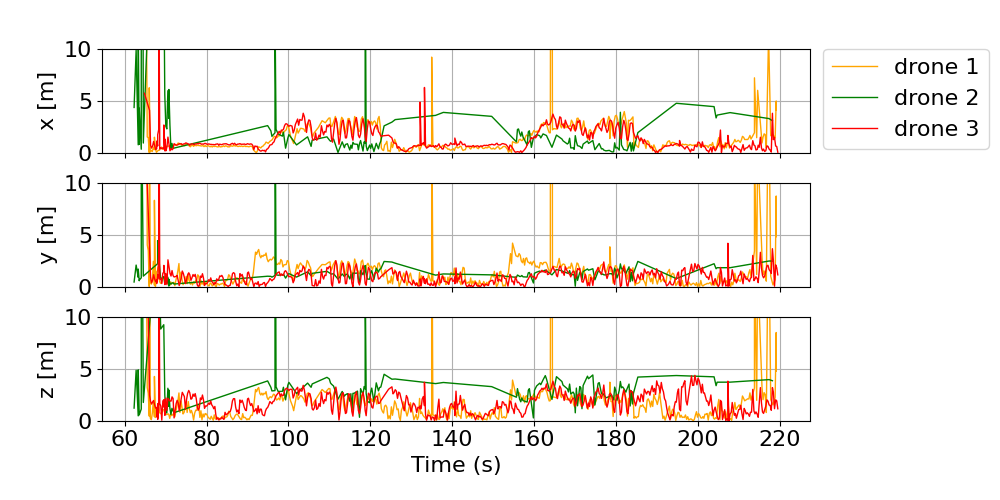

In [10]:
# Plot the absolute error of the detections for each drone
fig_abs_err = pu.plot_xyz_over_time(err_1_abs, label="drone 1", color="orange")
pu.plot_xyz_over_time(err_2_abs, fig=fig_abs_err, label="drone 2", noisy_limits=True, show_uncertainty=False, color="green")
pu.plot_xyz_over_time(err_3_abs, fig=fig_abs_err, label="drone 3", noisy_limits=True, show_uncertainty=False, color="red")
# Add legend
handles, labels = fig_abs_err.axes[0].get_legend_handles_labels()
fig_abs_err.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.925))
# fig_abs_err.legend(handles, labels, loc='upper right')
# fig_abs_err.suptitle("Absolute Error of Projected Measurements by Drone")
fig_abs_err.set_size_inches(10, 5)
fig_abs_err.tight_layout(rect=[0, 0, 1, 0.95])
fig_abs_err.subplots_adjust(right=0.81)  # Make room for the legend
fig_abs_err.axes[0].set_ylim((0, 10))
fig_abs_err.axes[1].set_ylim((0, 10))
fig_abs_err.axes[2].set_ylim((0, 10))
fig_abs_err.align_ylabels()

In [11]:
# fig_abs_err.savefig(os.path.join(PLOTS_DIR, "abs_projected_error.svg"), dpi=600, bbox_inches='tight')